# Epoch AI models database vs. the benchmark subjects

## 1. Setup

In [1]:
import difflib
import json
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROCESSED = ROOT / "data" / "processed"  # one <benchmark>.jsonl per benchmark, written by scripts/preprocess/*.py
EPOCH_ZIP = ROOT / "data" / "ai_models.zip"  # downloaded by scripts/preprocess/epoch_models_csv.py

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 200)

In [2]:
# Plot style, as in the benchmark notebooks. Blue = open weights, orange = closed.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb", "#e6e5e1"
GROUP_COLOR = {"open": BLUE, "closed": ORANGE}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.axisbelow": True, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.frameon": False, "legend.fontsize": 8.5,
    "lines.linewidth": 2, "figure.dpi": 110,
})


def panels(n, width=5.2, height=3.4):
    fig, axes = plt.subplots(1, n, figsize=(width * n, height), squeeze=False)
    return fig, axes[0]


def show(fig):
    fig.tight_layout()
    plt.show()

## 2. Read Raw Epoch File 

In [3]:
with zipfile.ZipFile(EPOCH_ZIP) as z, z.open("all_ai_models.csv") as f:
    epoch = pd.read_csv(f, parse_dates=["Publication date", "Last modified"], low_memory=False)
print(f"{len(epoch):,} models × {epoch.shape[1]} columns · names unique: {epoch.Model.is_unique} · "
      f"publication dates {epoch['Publication date'].min():%Y-%m} to {epoch['Publication date'].max():%Y-%m}")
print("Model accessibility:", epoch["Model accessibility"].value_counts(dropna=False).to_dict())
ACCESS = set(epoch["Model accessibility"].dropna())

3,627 models × 57 columns · names unique: True · publication dates 1950-07 to 2026-10
Model accessibility: {'Open weights (unrestricted)': 846, nan: 844, 'Unreleased': 833, 'API access': 436, 'Open weights (restricted use)': 303, 'Open weights (non-commercial)': 229, 'Hosted access (no API)': 133, 'Limited access': 3}


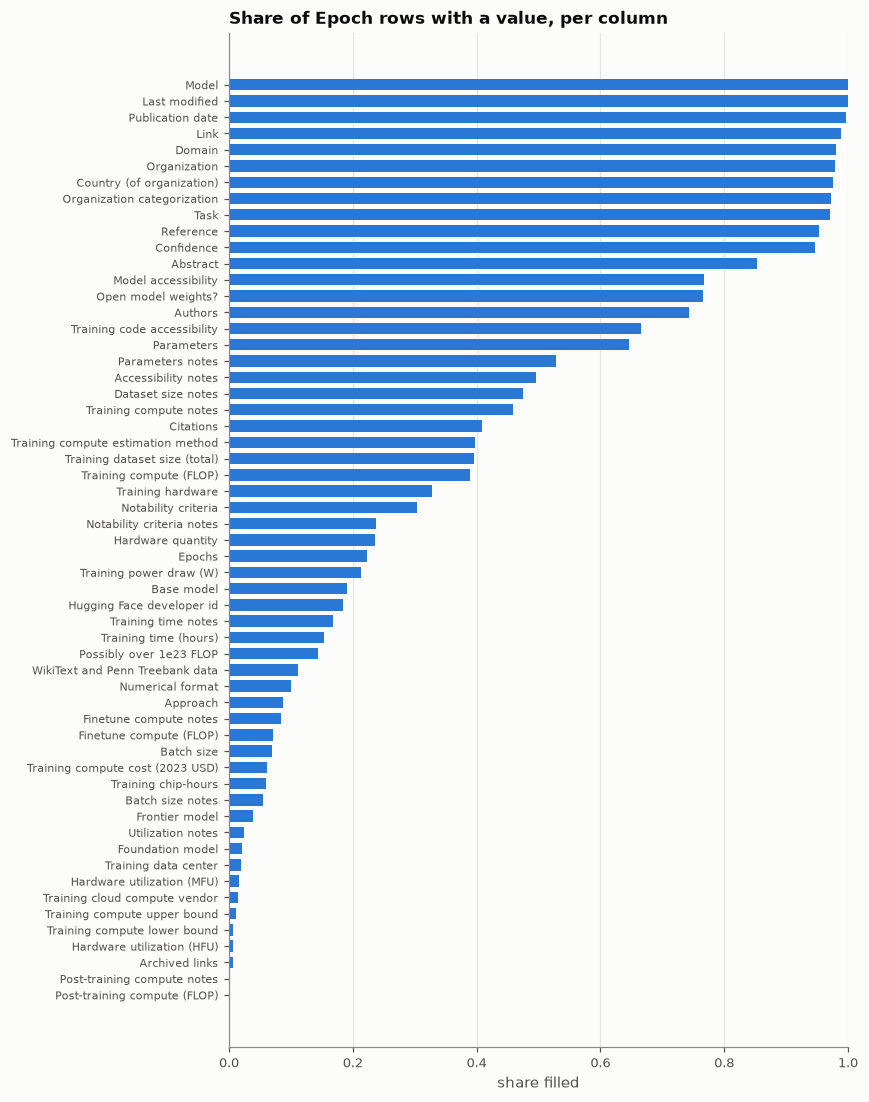

In [4]:
fill = epoch.notna().mean().sort_values(ascending=False)
fig, axes = panels(1, width=8, height=0.16 * len(fill) + 1)
ax = axes[0]
ax.barh(fill.index[::-1], fill.values[::-1], color=BLUE, height=0.7)
ax.set_xlim(0, 1)
ax.set_title("Share of Epoch rows with a value, per column")
ax.set_xlabel("share filled")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
show(fig)

## 3. Models in our benchmarks (post processing)

In [5]:
MODEL_FIELDS = ["benchmark", "subject_id", "model_name", "normalized_name", "provider", "release_date"]


def subjects_table(path):
    """One row per subject in a processed file. Streams the lines: some files hold long prompts."""
    seen = {}
    with open(path, encoding="utf-8") as f:
        for line in f:
            row = json.loads(line)
            seen.setdefault(row["subject_id"], {k: row[k] for k in MODEL_FIELDS})
    return pd.DataFrame(seen.values())


files = sorted(PROCESSED.glob("*.jsonl"))
print("processed files:", [f.name for f in files])
subj = (pd.concat([subjects_table(f) for f in files], ignore_index=True)
        .rename(columns={"model_name": "display_name"}))
models = (subj.groupby("normalized_name")
          .agg(provider=("provider", "first"), release_date=("release_date", "first"),
               benchmarks=("benchmark", lambda s: ", ".join(sorted(set(s)))), n_subjects=("subject_id", "size"),
               display_names=("display_name", lambda s: ", ".join(sorted(set(s)))))
          .reset_index())
print(f"{len(subj)} subjects in {subj.benchmark.nunique()} benchmarks → {len(models)} normalized names")
display(subj.groupby("benchmark").agg(subjects=("subject_id", "size"), normalized_names=("normalized_name", "nunique")))

processed files: ['matharena.jsonl', 'mmdocrag.jsonl', 'multi_swebench.jsonl', 'real_webagents.jsonl', 'researchcodebench.jsonl', 'swe_rebench.jsonl']


314 subjects in 6 benchmarks → 148 normalized names


,subjects,normalized_names
benchmark,,
matharena,104,79
mmdocrag,63,59
multi_swebench,82,20
real_webagents,33,33
researchcodebench,31,31
swe_rebench,1,1


In [6]:
# Entries that are not a single identifiable model: real_webagents leaderboard agents and test submissions.
NOT_A_MODEL = {"Test": "test submission", "Update Eval": "test submission",
               "KISS-1": "unidentified leaderboard entry", "Magellanes": "unidentified leaderboard entry"}
models["kind"] = np.where(models.normalized_name.str.startswith("Agent: "), "agent system",
                          models.normalized_name.map(NOT_A_MODEL).fillna("model"))
display(models[models.kind != "model"][["normalized_name", "kind", "benchmarks", "display_names"]])
print("model entries:", (models.kind == "model").sum())

,normalized_name,kind,benchmarks,display_names
0,Agent: AGI Agent 0,agent system,real_webagents,AGI agent 0
1,Agent: brassbunny,agent system,real_webagents,brassbunny
2,Agent: gbox,agent system,real_webagents,GBOX
3,Agent: iSWE,agent system,multi_swebench,Agent
4,Agent: iSWE-openmodels,agent system,multi_swebench,iSWE-OpenModels
75,KISS-1,unidentified leaderboard entry,real_webagents,KISS-1
77,Magellanes,unidentified leaderboard entry,real_webagents,Magellanes
133,Test,test submission,real_webagents,Test
134,Update Eval,test submission,real_webagents,Update Eval


model entries: 139


In [7]:
# Plain lookup: a name is found if its key (lower-case, letters and digits only), with or without the provider
# prefix, equals the key of an Epoch model name. §4 adds aliases, version dates and suffixes on top of this.
key = lambda s: re.sub(r"[^a-z0-9]", "", str(s).lower())


# Some rows have no provider (e.g. MathArena models whose name the preprocessing filled in), so strip any provider
# that appears elsewhere in the data, longest first.
PROVIDERS = sorted(set(subj.provider.dropna()), key=len, reverse=True)


def strip_provider(name, provider=None):
    for p in ([provider] if isinstance(provider, str) else []) + PROVIDERS:
        if name.lower().startswith(p.lower() + " "):
            return name[len(p):].strip()
    return name


epoch_keys = set(epoch.Model.map(key))
found = models.apply(lambda r: bool({key(r.normalized_name), key(strip_provider(r.normalized_name, r.provider))} & epoch_keys), axis=1)
not_found = models[(models.kind == "model") & ~found]
print(f"models not found in Epoch by name: {len(not_found)} of {(models.kind == 'model').sum()}")
display(not_found[["normalized_name", "provider", "benchmarks", "display_names"]].reset_index(drop=True))

models not found in Epoch by name: 23 of 139


,normalized_name,provider,benchmarks,display_names
0,Alibaba Qwen Max,Alibaba,mmdocrag,qwen-max
1,Alibaba Qwen-VL Plus,Alibaba,mmdocrag,qwen-vl-plus
2,Alibaba Qwen2.5-VL 32B,Alibaba,"mmdocrag, real_webagents","Qwen2.5 vl 32b instruct, qwen2.5-vl-32b"
3,Alibaba Qwen3-Coder 480B,Alibaba,swe_rebench,Qwen3-Coder-480B-A35B-Instruct
4,Alibaba Qwen3-VL 235B A22B,NaN,matharena,Qwen3-VL-235B Instruct
5,ByteDance Doubao 1.5 Thinking,ByteDance,multi_swebench,Doubao-1.5-thinking
6,DeepSeek V3.2 Speciale,NaN,matharena,"DeepSeek-v3.2-Speciale, DeepSeek-v3.2-Speciale Agent"
7,GAIR LIMO,NaN,matharena,LIMO
8,Google Gemini 2.5 Pro,Google,"matharena, mmdocrag, multi_swebench, real_webagents, researchcodeb...","GEMINI_2_5_PRO_PREVIEW_03_25, Gemini 2.5 Pro, Gemini 2.5 Pro (05-0..."
9,MBZUAI K2-Think,NaN,matharena,K2-Think


## 4. Matching names to Epoch

Names are converted to lower-case, with everything except letters and digits removed. What is compared:

1. **alias**: a hand-checked mapping for names Epoch spells differently (listed below, with the reason).
2. **exact**: same key, trying the name with and without the provider prefix ("DeepSeek R1" and "R1").
3. **exact, date dropped**: Epoch adds a version date in brackets, e.g. "Gemini 2.5 Pro (Mar 2025)".
4. **prefix**: Epoch's key is ours plus a known suffix (`a35b`, `instruct`, `preview`, a date…).

When several Epoch rows share the key, the most similar name wins, then the publication date closest to the
build's release date.

In [8]:
ALIASES = {
    "OpenAI GPT-4": ("GPT-4 Turbo (Apr 2024)",
                     "only subject is mmdocrag 'gpt-4-turbo'; the API alias points to gpt-4-turbo-2024-04-09"),
    "Mistral Small 24B": ("Mistral Small 3", "Mistral Small 3 is the 24B model released Jan 2025"),
    "OpenAI CUA": ("Computer-Using Agent (CUA)", "same system, Epoch spells the name out"),
    "Stanford s1.1 32B": ("s1.1", "Epoch lists s1.1 without the size"),
}
assert all(v[0] in set(epoch.Model) for v in ALIASES.values()), "alias target missing from Epoch"

epoch["key"] = epoch.Model.map(key)
epoch["key_nodate"] = epoch.Model.str.replace(r"\s*\([^)]*\)", "", regex=True).map(key)
SUFFIX = re.compile(r"^(a\d+b|instruct|it|chat|preview|exp|experimental|latest|\d{4}|\d{6})+$")


def match(row):
    if row.normalized_name in ALIASES:
        return "alias", epoch[epoch.Model == ALIASES[row.normalized_name][0]]
    names = {row.normalized_name, strip_provider(row.normalized_name, row.provider)}
    keys = {key(n) for n in names}
    for stage, col in [("exact", "key"), ("exact, date dropped", "key_nodate")]:
        c = epoch[epoch[col].isin(keys)]
        if len(c):
            return stage, c
    c = epoch[[any(k2.startswith(k) and SUFFIX.match(k2[len(k):]) for k in keys) for k2 in epoch.key_nodate]]
    return ("prefix", c) if len(c) else ("none", c)


def pick(cands, row):
    """Best candidate: most similar name, then publication date closest to the build's release date."""
    names = {row.normalized_name.lower(), strip_provider(row.normalized_name, row.provider).lower()}
    rel = pd.to_datetime(row.release_date, errors="coerce")
    sim = cands.Model.map(lambda m: max(difflib.SequenceMatcher(None, n, m.lower()).ratio() for n in names))
    gap = (cands["Publication date"] - rel).abs().dt.days if pd.notna(rel) else pd.Series(0, index=cands.index)
    return cands.assign(_sim=sim.round(2), _gap=gap.fillna(1e6)).sort_values(["_sim", "_gap"], ascending=[False, True]).index[0]


rows = []
for r in models[models.kind == "model"].itertuples():
    stage, cands = match(r)
    rows.append({"normalized_name": r.normalized_name, "stage": stage, "n_candidates": len(cands),
                 "epoch_index": pick(cands, r) if len(cands) else None,
                 "candidates": ", ".join(cands.Model.head(4))})
m = pd.DataFrame(rows)
m["epoch_model"] = m.epoch_index.map(lambda i: epoch.Model[i] if pd.notna(i) else None)
models = models.merge(m.drop(columns="epoch_index"), on="normalized_name", how="left")
models["epoch_index"] = models.normalized_name.map(m.set_index("normalized_name").epoch_index)
models["stage"] = models.stage.fillna("not a model")
display(models.stage.value_counts().rename("normalized names").to_frame())

,normalized names
stage,
exact,116
none,17
not a model,9
alias,4
prefix,1
"exact, date dropped",1


In [9]:
# Every non-exact match and every ambiguous one, to check by eye.
check = models[(models.stage.isin(["alias", "exact, date dropped", "prefix"])) | (models.n_candidates > 1)]
display(check[["normalized_name", "stage", "n_candidates", "epoch_model", "candidates"]].reset_index(drop=True))

,normalized_name,stage,n_candidates,epoch_model,candidates
0,Alibaba Qwen3-Coder 480B,prefix,1.0,Qwen3-Coder-480B-A35B,Qwen3-Coder-480B-A35B
1,Cohere Command A,exact,2.0,Cohere Command A,"Command A+, Cohere Command A"
2,Google Gemini 2.5 Pro,"exact, date dropped",3.0,Gemini 2.5 Pro (Mar 2025),"Gemini 2.5 Pro (Jun 2025), Gemini 2.5 Pro (May 2025), Gemini 2.5 P..."
3,Mistral Small 24B,alias,1.0,Mistral Small 3,Mistral Small 3
4,OpenAI CUA,alias,1.0,Computer-Using Agent (CUA),Computer-Using Agent (CUA)
5,OpenAI GPT-4,alias,1.0,GPT-4 Turbo (Apr 2024),GPT-4 Turbo (Apr 2024)
6,Stanford s1.1 32B,alias,1.0,s1.1,s1.1


In [10]:
miss = models[models.stage == "none"][["normalized_name", "provider", "benchmarks", "display_names"]]
print(f"models not in Epoch: {len(miss)}")
display(miss.reset_index(drop=True))

models not in Epoch: 17


,normalized_name,provider,benchmarks,display_names
0,Alibaba Qwen Max,Alibaba,mmdocrag,qwen-max
1,Alibaba Qwen-VL Plus,Alibaba,mmdocrag,qwen-vl-plus
2,Alibaba Qwen2.5-VL 32B,Alibaba,"mmdocrag, real_webagents","Qwen2.5 vl 32b instruct, qwen2.5-vl-32b"
3,Alibaba Qwen3-VL 235B A22B,NaN,matharena,Qwen3-VL-235B Instruct
4,ByteDance Doubao 1.5 Thinking,ByteDance,multi_swebench,Doubao-1.5-thinking
5,DeepSeek V3.2 Speciale,NaN,matharena,"DeepSeek-v3.2-Speciale, DeepSeek-v3.2-Speciale Agent"
6,GAIR LIMO,NaN,matharena,LIMO
7,MBZUAI K2-Think,NaN,matharena,K2-Think
8,Open Thoughts OpenThinker 32B,NaN,matharena,OpenThinker-32B
9,OpenBMB MiniCPM-o 2.6,OpenBMB,mmdocrag,minicpm-o-2.6-8b


## 5. Open vs. closed

In [11]:
mm = models[models.kind == "model"].copy()
e = epoch.loc[mm.epoch_index.dropna().astype(int)].set_index(mm.loc[mm.epoch_index.notna(), "normalized_name"])


def epoch_open(row):
    acc, flag = row["Model accessibility"], row["Open model weights?"]
    if acc in ACCESS:
        return acc.startswith("Open weights")
    return {"Yes": True, "No": False}.get(flag)


mm["open"] = mm.normalized_name.map(e.apply(epoch_open, axis=1))
mm["group"] = mm.open.map({True: "open", False: "closed"}).fillna("unknown")
display(mm.group.value_counts().rename("models").to_frame())
print("unknown (not in Epoch, or no accessibility):", mm.loc[mm.group == "unknown", "normalized_name"].tolist())

,models
group,
open,64
closed,57
unknown,18


unknown (not in Epoch, or no accessibility): ['Alibaba QVQ-Max', 'Alibaba Qwen Max', 'Alibaba Qwen-VL Plus', 'Alibaba Qwen2.5-VL 32B', 'Alibaba Qwen3-VL 235B A22B', 'ByteDance Doubao 1.5 Thinking', 'DeepSeek V3.2 Speciale', 'GAIR LIMO', 'MBZUAI K2-Think', 'Open Thoughts OpenThinker 32B', 'OpenBMB MiniCPM-o 2.6', 'OpenGVLab InternVL2.5 8B', 'OpenGVLab InternVL3 14B', 'OpenGVLab InternVL3 38B', 'OpenGVLab InternVL3 78B', 'OpenGVLab InternVL3 8B', 'OpenGVLab InternVL3 9B', 'QED-Nano']


## 6. Epoch data analysis 

In [12]:
FIELDS = {
    "Publication date": "release_date",
    "Parameters": "params_total_b",
    "Training compute (FLOP)": "(feature)",
    "Training dataset size (total)": "(feature)",
    "Domain": "multimodal_input",
    "Model accessibility": "open_weights",
    "Base model": "model_family",
    "Organization": "provider",
    "Country (of organization)": "(feature)",
    "Post-training compute (FLOP)": "(feature)",
    "Finetune compute (FLOP)": "(feature)",
    "Training hardware": "(feature)",
    "Frontier model": "(feature)",
    "Confidence": "(quality flag)",
}
mm = mm.join(e[list(FIELDS)], on="normalized_name")
cov = (mm[mm.stage.isin(["exact", "exact, date dropped", "prefix", "alias"])]
       .groupby("group")[list(FIELDS)].agg(lambda s: s.notna().mean()).T)
cov.insert(0, "our column", pd.Series(FIELDS))
n_in = mm[mm.epoch_index.notna()].group.value_counts()
print("models in Epoch:", n_in.to_dict(), "· not in Epoch:", mm[mm.epoch_index.isna()].group.value_counts().to_dict())
display(cov.round(2))

models in Epoch: {'open': 64, 'closed': 57, 'unknown': 1} · not in Epoch: {'unknown': 17}


group,our column,closed,open,unknown
Publication date,release_date,1.00,1.00,1.0
Parameters,params_total_b,0.05,0.97,0.0
Training compute (FLOP),(feature),0.12,0.62,0.0
Training dataset size (total),(feature),0.02,0.38,0.0
Domain,multimodal_input,0.96,0.98,1.0
Model accessibility,open_weights,1.00,1.00,0.0
Base model,model_family,0.02,0.30,0.0
Organization,provider,1.00,1.00,1.0
Country (of organization),(feature),1.00,1.00,1.0
Post-training compute (FLOP),(feature),0.00,0.00,0.0


In [13]:
def presence_map(group):
    d = mm[(mm.group == group) & mm.epoch_index.notna()].set_index("normalized_name")[list(FIELDS)].notna()
    d = d.loc[d.sum(axis=1).sort_values(ascending=False).index]
    fig, axes = panels(1, width=8, height=0.17 * len(d) + 1.6)
    ax = axes[0]
    ax.imshow(d.values, aspect="auto", cmap=ListedColormap([GRID, GROUP_COLOR[group]]), vmin=0, vmax=1)
    ax.set_xticks(range(len(FIELDS)))
    ax.set_xticklabels([c.replace(" (", "\n(") for c in FIELDS], rotation=60, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(d.index, fontsize=7)
    ax.set_title(f"{group.capitalize()} models: Epoch fields present (coloured) or missing ({len(d)} models)")
    ax.grid(False)
    show(fig)

### 6.1 Open-weight models

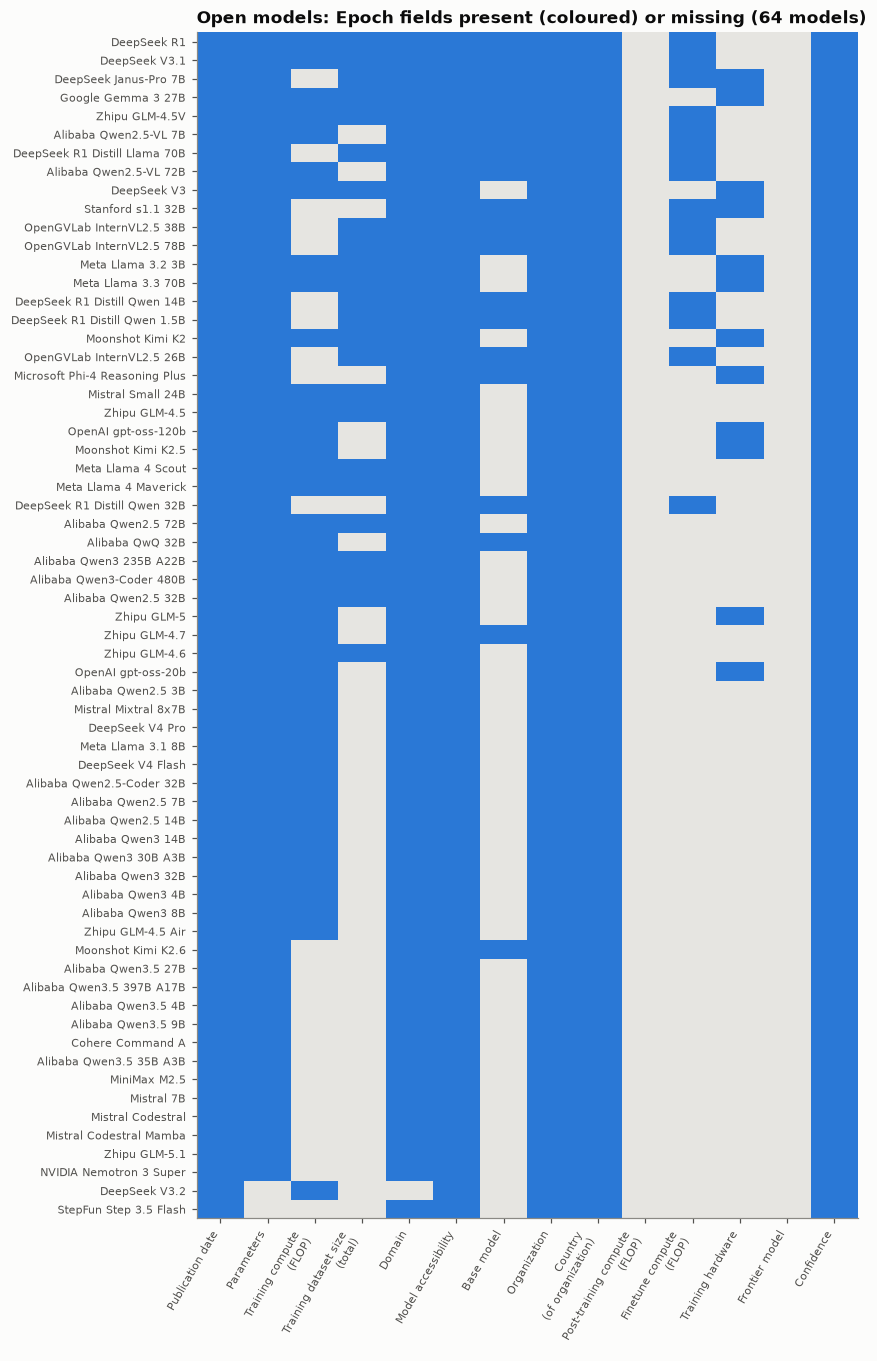

In [14]:
presence_map("open")

In [15]:
op = mm[(mm.group == "open") & mm.epoch_index.notna()]
print(f"parameters known: {op.Parameters.notna().sum()} of {len(op)} · training compute known: "
      f"{op['Training compute (FLOP)'].notna().sum()} · dataset size known: {op['Training dataset size (total)'].notna().sum()}")
print("missing parameters:", op.loc[op.Parameters.isna(), "normalized_name"].tolist())
print("missing training compute:", op.loc[op["Training compute (FLOP)"].isna(), "normalized_name"].tolist())

parameters known: 62 of 64 · training compute known: 40 · dataset size known: 24
missing parameters: ['DeepSeek V3.2', 'StepFun Step 3.5 Flash']
missing training compute: ['Alibaba Qwen3.5 27B', 'Alibaba Qwen3.5 35B A3B', 'Alibaba Qwen3.5 397B A17B', 'Alibaba Qwen3.5 4B', 'Alibaba Qwen3.5 9B', 'Cohere Command A', 'DeepSeek Janus-Pro 7B', 'DeepSeek R1 Distill Llama 70B', 'DeepSeek R1 Distill Qwen 1.5B', 'DeepSeek R1 Distill Qwen 14B', 'DeepSeek R1 Distill Qwen 32B', 'Microsoft Phi-4 Reasoning Plus', 'MiniMax M2.5', 'Mistral 7B', 'Mistral Codestral', 'Mistral Codestral Mamba', 'Moonshot Kimi K2.6', 'NVIDIA Nemotron 3 Super', 'OpenGVLab InternVL2.5 26B', 'OpenGVLab InternVL2.5 38B', 'OpenGVLab InternVL2.5 78B', 'Stanford s1.1 32B', 'StepFun Step 3.5 Flash', 'Zhipu GLM-5.1']


### 6.2 Closed models

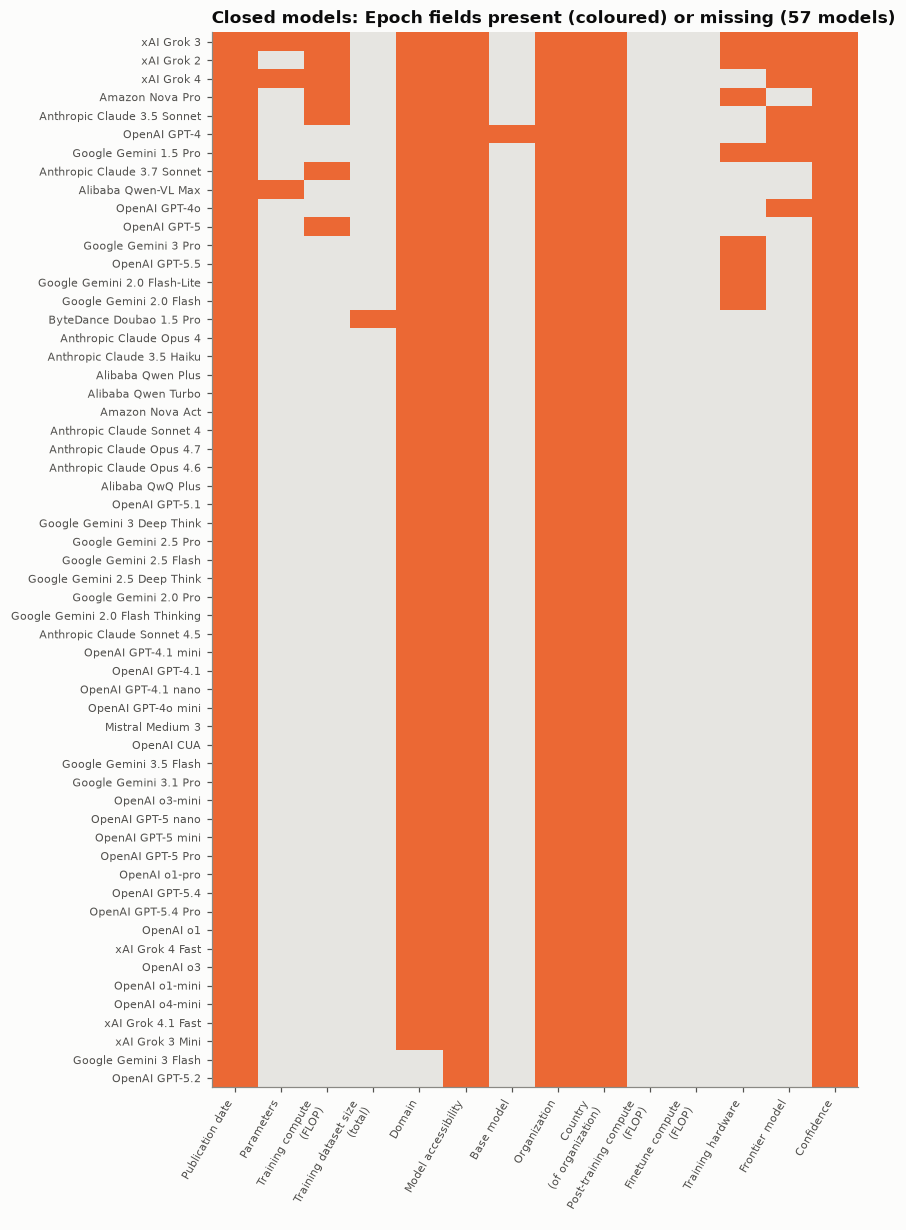

In [16]:
presence_map("closed")

In [17]:
cl = mm[(mm.group == "closed") & mm.epoch_index.notna()]
print(f"parameters known: {cl.Parameters.notna().sum()} of {len(cl)} · training compute known: "
      f"{cl['Training compute (FLOP)'].notna().sum()} · dataset size known: {cl['Training dataset size (total)'].notna().sum()}")
print("with parameters:", cl.loc[cl.Parameters.notna(), ["normalized_name", "Parameters"]].values.tolist())
print("confidence of the compute estimates:", cl.loc[cl["Training compute (FLOP)"].notna(), "Confidence"].value_counts().to_dict())

parameters known: 3 of 57 · training compute known: 7 · dataset size known: 1
with parameters: [['Alibaba Qwen-VL Max', 7000000000.0], ['xAI Grok 3', 3000000000000.0], ['xAI Grok 4', 3000000000000.0]]
confidence of the compute estimates: {'Speculative': 4, 'Likely': 2, 'Confident': 1}


## 7. Consistency with the build

In [19]:
mm["release_build"] = pd.to_datetime(mm.release_date, errors="coerce")
mm["date_gap_days"] = (mm["Publication date"] - mm.release_build).dt.days
d = mm.dropna(subset=["date_gap_days"])
print(f"release date (build) vs publication date (Epoch), {len(d)} models: same day {(d.date_gap_days == 0).mean():.0%}, "
      f"within 31 days {(d.date_gap_days.abs() <= 31).mean():.0%}")
display(d.loc[d.date_gap_days.abs() > 31, ["normalized_name", "release_date", "Publication date", "date_gap_days", "epoch_model"]]
        .sort_values("date_gap_days").reset_index(drop=True))

release date (build) vs publication date (Epoch), 105 models: same day 74%, within 31 days 92%


,normalized_name,release_date,Publication date,date_gap_days,epoch_model
0,Google Gemini 2.0 Pro,2025-02-05,2024-12-11,-56.0,Gemini 2.0 Pro
1,Alibaba QwQ Plus,2025-03-05,2025-04-08,34.0,QWQ-Plus
2,OpenAI o3-mini,2024-12-20,2025-01-31,42.0,o3-mini
3,OpenAI GPT-5 Pro,2025-08-07,2025-10-07,61.0,GPT-5 Pro
4,DeepSeek V3.2,2025-09-29,2025-12-01,63.0,DeepSeek-V3.2
5,Alibaba QwQ 32B,2024-11-28,2025-03-06,98.0,QwQ-32B
6,Alibaba Qwen Plus,2023-09-01,2024-02-06,158.0,Qwen Plus
7,OpenAI GPT-4,2023-03-14,2024-04-09,392.0,GPT-4 Turbo (Apr 2024)
